# What does the model remember about a bar?

*Question 1 of the latent-space analysis.*

The model squeezes every bar of music into a list of 512 numbers, its **latent code**, and
must rebuild the bar from those numbers alone. So what survives the squeeze? A faithful
snapshot of the notes, or only a rough sketch? And does the code capture things the model was
never told about, like the key of the piece?

We compare three versions of the code:

- the **compact** model (β = 0.1), which pays a high price for every bit of information it
  stores about a bar;
- the **detailed** model (β = 0.01), which pays ten times less, and so stores much more;
- an **untrained** model: the same architecture with random weights. It is our *control*:
  whatever it also seems to "know" comes from the architecture, not from learning.

The sound examples are saved as MP3 and MIDI files in `outputs/q1`, with a link below each
example. Every measurement uses bars from the 60 **validation pieces**, which the models never saw
during training. Running this notebook takes about 25 minutes on a laptop CPU, mostly for
section 3.

In [1]:
import os
from pathlib import Path

root = Path.cwd()
while not (root / "pyproject.toml").exists():
    root = root.parent
os.chdir(root)  # paths below are relative to the repository root

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from pianotree_dcml.analysis.audio import save_mp3, synthesize, to_midi
from pianotree_dcml.analysis.decode import decode
from pianotree_dcml.analysis.encode import dataset_for, load_embeddings
from pianotree_dcml.analysis.features import bar_features, notes_table
from pianotree_dcml.analysis.latent import kl_per_dimension, sample_prior
from pianotree_dcml.analysis.plots import plot_bars, plot_probe_results
from pianotree_dcml.analysis.probes import detector_accuracy, run_probes
from pianotree_dcml.analysis.reconstruction import bar_scores
from pianotree_dcml.data.keys import is_minor, tonic_pitch_class
from pianotree_dcml.train import load_checkpoint

OUT = Path("notebooks/outputs/q1")  # figures and sounds, e.g. for a blog post
OUT.mkdir(parents=True, exist_ok=True)

def listen(path):
    # A link to a sound file; audio players are kept out of the notebook to keep it small.
    display(Markdown(f"Listen: [{path.name}]({path.relative_to('notebooks').as_posix()})"))


RUNS = {"compact (β = 0.1)": "runs/full", "detailed (β = 0.01)": "runs/full_beta0.01"}
COLORS = {"compact (β = 0.1)": "tab:blue", "detailed (β = 0.01)": "tab:orange",
          "untrained": "tab:gray"}
models = {name: load_checkpoint(f"{run}/best.pt")[0] for name, run in RUNS.items()}
codes = {name: load_embeddings(f"{run}/embeddings.npz") for name, run in RUNS.items()}
codes["untrained"] = load_embeddings("runs/full/embeddings_untrained.npz")

bars = codes["compact (β = 0.1)"].bars
dataset = dataset_for(codes["compact (β = 0.1)"])
features = bar_features(dataset.notes_table(), bars.bar_len)
valid = (bars.split == "valid").to_numpy()
train = ~valid
pieces = (bars.corpus + "/" + bars.piece).to_numpy()
print(f"{valid.sum()} validation bars from {len(set(pieces[valid]))} pieces")

6461 validation bars from 60 pieces


## 1. How much room does a bar take up in the code?

For each of the 512 numbers, we can measure how much the encoder departs from "I know
nothing about this bar". That measure, the KL divergence, is counted in *nats*
(1 nat ≈ 1.44 bits). Adding it over the 512 numbers gives the amount of information the
code holds about a bar, on average.

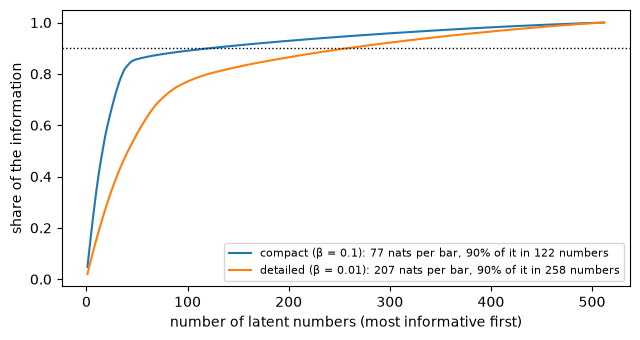

In [2]:
fig, ax = plt.subplots(figsize=(6.5, 3.5))
for name in RUNS:
    kl = kl_per_dimension(codes[name].mean[valid], codes[name].scale[valid])
    share = np.cumsum(np.sort(kl)[::-1]) / kl.sum()
    n90 = np.searchsorted(share, 0.9) + 1
    ax.plot(np.arange(1, 513), share, color=COLORS[name],
            label=f"{name}: {kl.sum():.0f} nats per bar, 90% of it in {n90} numbers")
ax.axhline(0.9, color="k", linestyle=":", linewidth=1)
ax.set_xlabel("number of latent numbers (most informative first)")
ax.set_ylabel("share of the information")
ax.legend(fontsize=8, loc="lower right")
fig.tight_layout()
fig.savefig(OUT / "information_per_number.png", dpi=150)

Both models spread their information unevenly. The **compact** model holds about 77 nats
(roughly 110 bits) per bar, and 90% of it sits in 122 of the 512 numbers; the rest carry
little. The **detailed** model holds almost three times as much, about 207 nats, spread over
twice as many numbers.

The untrained model isn't shown: with random weights, its codes barely move away from "I know
nothing" (about 1 nat per bar), yet, as we'll see in section 3, those small movements still
carry a surprising amount of information.

## 2. Can it play back music it has never heard?

We encode each validation bar, decode it again, and count the notes that come back exactly
right (same start, pitch and length). The score per bar is an F1: 1 means every note is right
and no wrong note was added; 0.5 means about half of them.

In [3]:
originals = [dataset.notes(i) for i in np.flatnonzero(valid)]
playback = {name: decode(model, codes[name].mean[valid]) for name, model in models.items()}
scores = pd.concat([
    bar_scores(originals, playback[name]).assign(model=name, corpus=bars.corpus[valid].to_numpy(),
                                                 year=bars.year[valid].to_numpy(),
                                                 n_notes=features.n_notes[valid].to_numpy())
    for name in RUNS])

summary = scores.groupby("model", sort=False).agg(
    average_F1=("note_f1", "mean"), perfect_bars=("note_f1", lambda f: (f == 1).mean()))
display(summary.style.format({"average_F1": "{:.2f}", "perfect_bars": "{:.0%}"}))

,average_F1,perfect_bars
model,,
compact (β = 0.1),0.86,46%
detailed (β = 0.01),0.94,68%


model,pieces,year,compact (β = 0.1),detailed (β = 0.01)
corpus,,,,
corelli,14,1689,0.90,0.97
mozart_piano_sonatas,7,1783,0.89,0.96
beethoven_piano_sonatas,7,1802,0.90,0.97
ABC,8,1806,0.84,0.92
schumann_kinderszenen,2,1839,0.76,0.86
chopin_mazurkas,7,1842,0.95,0.99
liszt_pelerinage,3,1855,0.81,0.94
tchaikovsky_seasons,2,1876,0.62,0.84
dvorak_silhouettes,1,1879,1.00,1.00


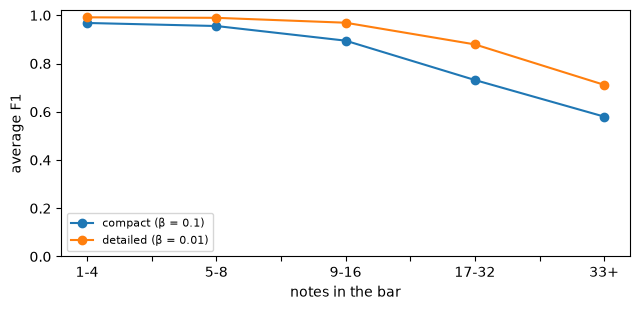

In [4]:
by_corpus = scores.pivot_table(index="corpus", columns="model", values="note_f1",
                               aggfunc="mean", sort=False)
by_corpus.insert(0, "pieces", bars[valid].groupby("corpus").piece.nunique())
by_corpus.insert(1, "year", bars[valid].groupby("corpus").year.median().astype(int))
display(by_corpus.sort_values("year").style.format("{:.2f}", subset=list(RUNS)))

fig, ax = plt.subplots(figsize=(6.5, 3.2))
bins = pd.cut(scores.n_notes, [0, 4, 8, 16, 32, 200], labels=["1-4", "5-8", "9-16", "17-32", "33+"])
for name in RUNS:
    scores[scores.model == name].groupby(bins[scores.model == name], observed=True).note_f1.mean() \
        .plot(ax=ax, marker="o", color=COLORS[name], label=name)
ax.set_xlabel("notes in the bar")
ax.set_ylabel("average F1")
ax.set_ylim(0, 1.02)
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(OUT / "playback_by_density.png", dpi=150)

These scores average one score per bar. The validation F1 reported during training (0.80
and 0.91) pools all notes instead, so busy bars, which are the hardest, weigh more there:
both views are right, they answer different questions.

The **detailed** model plays back new bars almost perfectly (two bars in three come back
without a single mistake); the **compact** model gets almost half of them perfect. Both
struggle as bars get busier: with more than 32 notes, the compact model gets barely 60% of
them right, as it simply has too little room in its code.

The table hints at something we'll come back to in question 4: the bars of the latest
composers (Debussy, Tchaikovsky, Medtner) are the hardest to play back. Part of that is
density, but with only one to three validation pieces for these corpora, it is only a hint.

Let's listen. The two examples below were chosen to be *typical*, not cherry-picked: a bar
of medium density whose score is the median for its group, and a busy bar (more than 32
notes) with its group's median score. Each plays the original, then the compact model's
version, then the detailed model's.

medium bar: Ludwig van Beethoven, n08op59-2_04 (bar 42), 16 notes


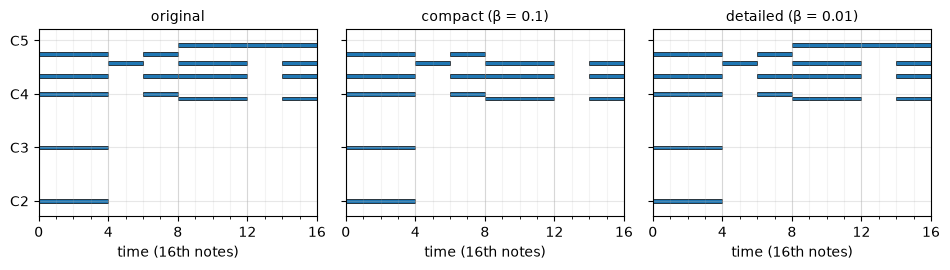

Listen: [playback_medium.mp3](outputs/q1/playback_medium.mp3)

busy bar: Claude Debussy, l075-02_suite_menuet (bar 6), 36 notes


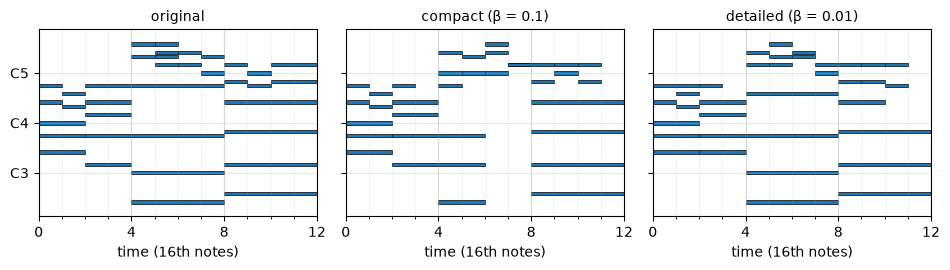

Listen: [playback_busy.mp3](outputs/q1/playback_busy.mp3)

In [5]:
def typical_bar(low, high):
    # The validation bar with low < notes <= high whose compact score is closest to the median.
    compact = scores[scores.model == "compact (β = 0.1)"].reset_index(drop=True)
    group = compact[(compact.n_notes > low) & (compact.n_notes <= high)]
    return group.index[(group.note_f1 - group.note_f1.median()).abs().argmin()]

examples = {"medium": typical_bar(8, 16), "busy": typical_bar(32, 200)}
for label, k in examples.items():
    i = np.flatnonzero(valid)[k]
    info = bars.loc[i]
    versions = [originals[k]] + [playback[name][k] for name in RUNS]
    lengths = [int(info.bar_len)] * 3
    print(f"{label} bar: {info.composer}, {info.piece} (bar {info.mn}), {len(originals[k])} notes")
    fig = plot_bars(versions, ["original"] + list(RUNS), lengths)
    fig.savefig(OUT / f"playback_{label}.png", dpi=150)
    plt.show()
    save_mp3(synthesize(versions, lengths, gap_steps=4), OUT / f"playback_{label}.mp3")
    to_midi(versions, OUT / f"playback_{label}.mid", lengths, gap_steps=4)
    listen(OUT / f"playback_{label}.mp3")

## 3. What can be read from the code?

Playing back a bar shows that the code holds *enough* to rebuild it, but not *how* the
information is stored. To find out, we train a **probe**: a deliberately simple (linear)
model that tries to read a property of the bar, like its register or its key, directly from
its 512 numbers. The probe learns on bars of the training pieces and is tested on bars of the
validation pieces. If it succeeds, the code holds that property in a plain, easily readable
form.

Scores are on a common scale where 1 is perfect. For numbers (register, note length...), the
score is the share of the differences between bars that the probe predicts (R²; 0 means no
better than always guessing the average). For categories (meter, key...), it is the share of
each category recognised on average (balanced accuracy); the dotted line marks pure guessing.
Error bars show the uncertainty from having only 60 test pieces.

The properties fall in three groups:

- **what the bar looks like** on a piano roll: how high, how many notes, how long, where in
  the beat they start, how long the bar is (its meter);
- **texture**: how much the melody leaps, how dissonant (tense-sounding) the notes played together are, how many
  different note names the bar uses;
- **musical context**, which no single note shows: whether the piece is in a major or a minor
  key, which of the 12 keys, and whether the bar opens on a major or a minor chord.

In [6]:
mode = bars.key.map(lambda k: "minor" if is_minor(k) else "major", na_action="ignore")
chord = bars.chord_type.where(bars.chord_type.isin(["M", "m"])).map({"M": "major", "m": "minor"})
targets = {
    "register (average pitch)": ("number", features.pitch_mean),
    "lowest note": ("number", features.pitch_lowest),
    "highest note": ("number", features.pitch_highest),
    "number of notes": ("number", features.n_notes),
    "notes played together": ("number", features.chord_size),
    "note length": ("number", features.duration_mean),
    "offbeat notes": ("number", features.offbeat_onsets),
    "meter (bar length)": ("category", bars.bar_len),
    "melodic leaps": ("number", features.top_line_leap),
    "dissonance": ("number", features.dissonance),
    "variety of note names": ("number", features.pitch_class_entropy),
    "major or minor key": ("category", mode),
    "which key (12 options)": ("category", bars.key.map(tonic_pitch_class, na_action="ignore")),
    "opening chord major or minor": ("category", chord),
}
probes = run_probes({name: e.mean for name, e in codes.items()}, targets, train, valid, pieces)

Major and minor keys use different notes, but which notes depends on the key: E♭ is the
minor-key note over C, while G♭ plays that role over E♭. A linear probe can't easily follow
that. So we also try with every piece transposed to C major or C minor before encoding
(pieces without an annotated key are left out), where "minor" simply means E♭, A♭ and B♭
instead of E, A and B.

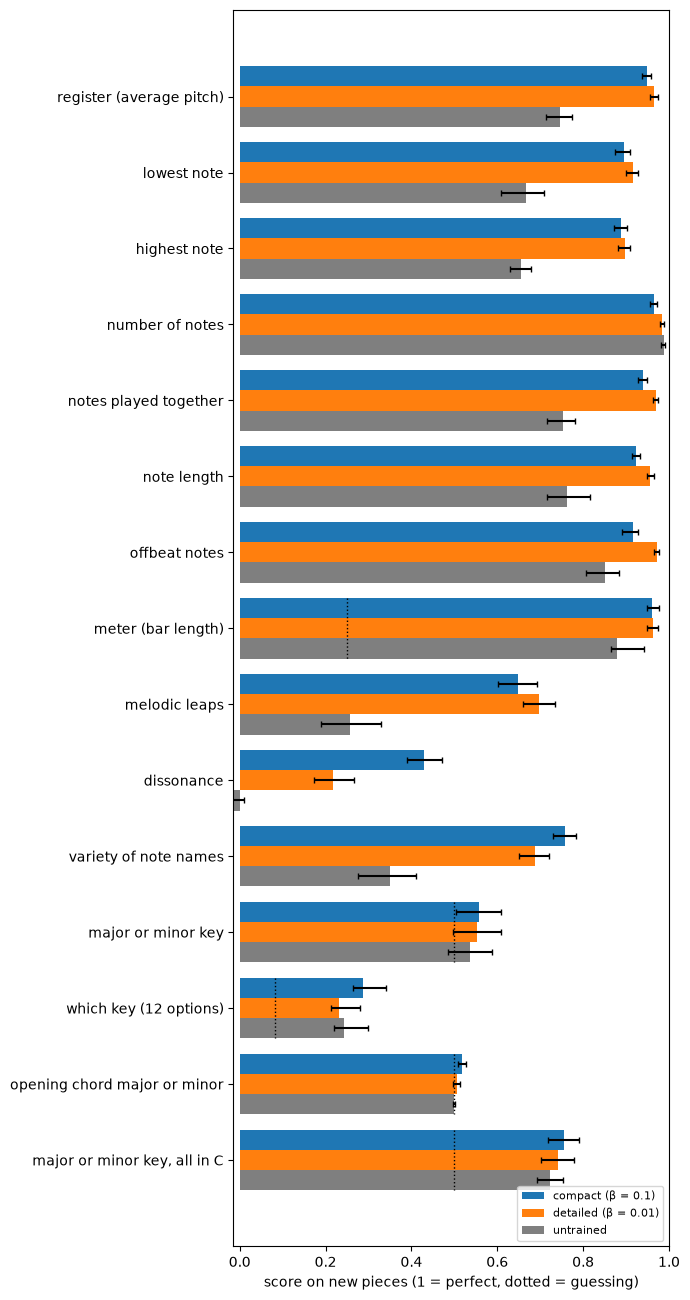

codes,compact (β = 0.1),detailed (β = 0.01),untrained
property,,,
register (average pitch),0.95,0.97,0.75
lowest note,0.89,0.92,0.67
highest note,0.89,0.90,0.66
number of notes,0.96,0.98,0.99
notes played together,0.94,0.97,0.75
note length,0.92,0.96,0.76
offbeat notes,0.92,0.97,0.85
meter (bar length),0.96,0.96,0.88
melodic leaps,0.65,0.70,0.26


In [7]:
aligned = {"compact (β = 0.1)": "runs/full/embeddings_to_c.npz",
           "detailed (β = 0.01)": "runs/full_beta0.01/embeddings_to_c.npz",
           "untrained": "runs/full/embeddings_to_c_untrained.npz"}
aligned = {name: load_embeddings(path) for name, path in aligned.items()}
a_bars = aligned["untrained"].bars
a_valid = (a_bars.split == "valid").to_numpy()
a_mode = a_bars.key.map(lambda k: "minor" if is_minor(k) else "major")
probes = pd.concat([probes, run_probes(
    {name: e.mean for name, e in aligned.items()},
    {"major or minor key, all in C": ("category", a_mode)},
    ~a_valid, a_valid, (a_bars.corpus + "/" + a_bars.piece).to_numpy())])

ax = plot_probe_results(probes, COLORS)
ax.figure.tight_layout()
ax.figure.savefig(OUT / "probes.png", dpi=150)
plt.show()
display(probes.pivot_table(index="property", columns="codes", values="score", sort=False).round(2))

*Dissonance* here is the share of pairs of notes starting together that sound tense: a
semitone, a whole tone, a tritone or a seventh apart (ignoring octaves). It is a rough
measure: it ignores notes that are held while others start, and the musical context that
often makes dissonance expressive rather than wrong.

Three findings stand out.

**The code is first and foremost a picture of the piano roll.** Register, number of notes,
how many play together, how long they are and the meter can all be read almost perfectly
(scores around 0.9 to 0.98) from both trained models. That makes sense: it is exactly what the
model needs to play the bar back.

**The untrained control knows a lot "for free".** Even with random weights, the architecture
turns bars into codes from which the number of notes (0.99!), the offbeat notes and the meter
can be read. Training matters most for *where* the notes are (register: 0.75 untrained vs 0.95
compact) and for texture: melodic leaps (0.26 vs 0.65), dissonance (about 0 vs 0.43),
variety of note names (0.35 vs 0.76). Without the control, we would have credited training for
everything.

**Musical context is barely there, or not in a readable form.** A single bar says little
about whether its piece is major or minor (0.56, where guessing gets 0.50) or about its opening
chord (at chance). Once all pieces are moved to C, the mode becomes readable (0.76), but almost
as well from the untrained codes (0.72): the information is in the notes themselves, and the
model doesn't organise its codes around it. The key itself is slightly readable (0.29, where
guessing gets 0.08), but the control does almost as well (0.24).

Notice also that the **detailed** model, despite holding three times more information, is
*worse* than the compact one at texture (dissonance: 0.22 vs 0.43). Storing more detail
doesn't make the code easier to read: squeezing harder forces the compact model to keep things
more orderly.

## 4. What lives between the bars?

The code space isn't only a filing system for real bars: any point in it can be decoded. If the
model has organised it well, random points should decode into bars that look and sound like
music. We draw 1,000 random codes for each model (from the standard normal distribution the
models were trained to fill) and compare their bars with real 16-step bars from the validation
pieces.

,notes per bar (median),register (average),notes played together,dissonance,detector accuracy
real bars,14.0,62.69,2.27,0.15,NaN
compact (β = 0.1),12.0,63.19,2.27,0.15,0.83
detailed (β = 0.01),13.0,63.39,2.30,0.31,0.91


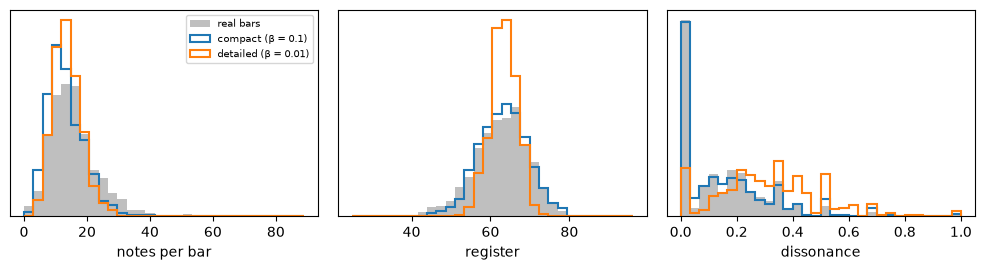

In [8]:
real = features[valid & (bars.bar_len == 16).to_numpy()]
generated = {name: decode(model, sample_prior(1000, 512, seed=0)) for name, model in models.items()}
gen_features = {name: bar_features(notes_table(b), pd.Series([16] * len(b)))
                for name, b in generated.items()}

comparison = pd.DataFrame({
    name: {"notes per bar (median)": f.n_notes.median(),
           "register (average)": f.pitch_mean.mean(),
           "notes played together": f.chord_size.mean(),
           "dissonance": f.dissonance.mean(),
           "detector accuracy": detector_accuracy(real, f)}
    for name, f in [("real bars", real)] + list(gen_features.items())}).T
comparison.loc["real bars", "detector accuracy"] = np.nan
display(comparison.round(2))

fig, axes = plt.subplots(1, 3, figsize=(10, 2.8))
for ax, (column, label) in zip(axes, [("n_notes", "notes per bar"), ("pitch_mean", "register"),
                                      ("dissonance", "dissonance")]):
    values = [real[column].dropna()] + [f[column].dropna() for f in gen_features.values()]
    bins = np.histogram_bin_edges(np.concatenate(values), bins=30)
    ax.hist(values[0], bins, density=True, color="k", alpha=0.25, label="real bars")
    for name, v in zip(gen_features, values[1:]):
        ax.hist(v, bins, density=True, histtype="step", linewidth=1.5, color=COLORS[name], label=name)
    ax.set_xlabel(label)
    ax.set_yticks([])
axes[0].legend(fontsize=7)
fig.tight_layout()
fig.savefig(OUT / "random_bars_vs_real.png", dpi=150)

The *detector accuracy* is how often a simple classifier, looking at the features of a bar,
can tell a random bar from a real one: 0.5 would mean it can't tell them apart at all.

The **compact** model's random bars are close to real ones: the same spread of registers, as
many notes played together, and exactly as much dissonance as real music (0.15 for both). They are only a little sparser (12 notes per bar, against 14). They aren't
indistinguishable, as the detector still catches them 83% of the time, but they are close.
The **detailed** model's random bars keep to a narrower band of registers and are twice as
dissonant as real music (0.31 against 0.15), and the detector catches them 91% of the time. Listen
for yourself: four random bars from each model.

compact (β = 0.1)


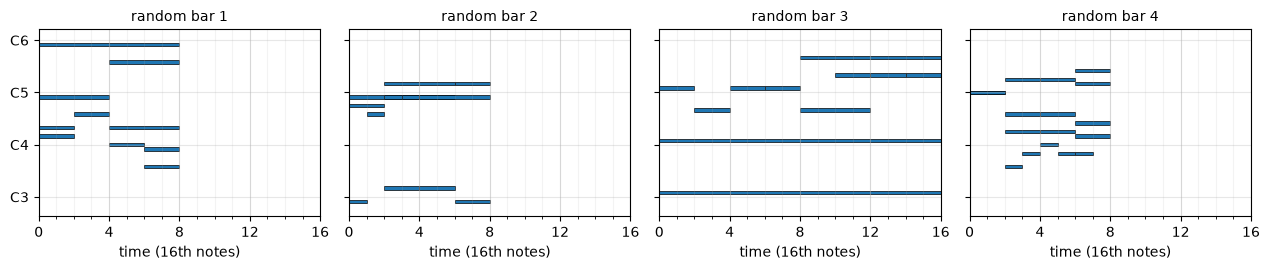

Listen: [random_bars_compact.mp3](outputs/q1/random_bars_compact.mp3)

detailed (β = 0.01)


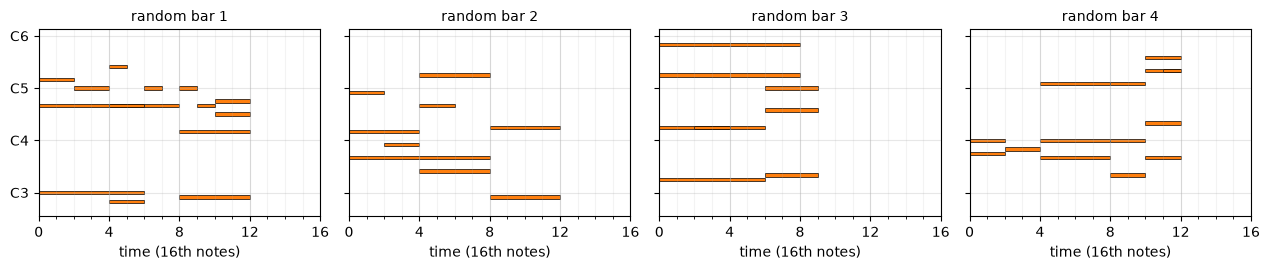

Listen: [random_bars_detailed.mp3](outputs/q1/random_bars_detailed.mp3)

In [9]:
for name, b in generated.items():
    sample = b[:4]
    print(name)
    fig = plot_bars(sample, [f"random bar {k + 1}" for k in range(4)], [16] * 4, color=COLORS[name])
    fig.savefig(OUT / f"random_bars_{name.split()[0]}.png", dpi=150)
    plt.show()
    save_mp3(synthesize(sample, [16] * 4, gap_steps=4), OUT / f"random_bars_{name.split()[0]}.mp3")
    to_midi(sample, OUT / f"random_bars_{name.split()[0]}.mid", [16] * 4, gap_steps=4)
    listen(OUT / f"random_bars_{name.split()[0]}.mp3")

## Summary

- **The code is mostly a picture of the piano roll.** Where the notes are, how many, how long:
  all of it can be read back almost perfectly, which is what the model needs to play bars back.
- **The architecture alone gives a head start.** A random, untrained version of the model
  already produces codes that reveal the number of notes or the meter. Training adds most for
  pitch and texture: register, melodic leaps, dissonance.
- **Context is not what the code is organised around.** Key, mode and chords are at best
  faintly readable from a single bar, and mostly through the notes themselves.
- **There is a trade-off between memory and order.** The detailed model plays back new music
  better (two bars in three perfectly), but the compact model keeps its code tidier: texture is
  easier to read, and random points decode into more realistic music.

For the next questions, that last point matters. To *move around* the space (question 2), the
compact model is the better candidate. To ask what the code reveals about composers and eras
(question 4), we'll keep both, together with the untrained control, and check whether the
answer goes beyond the simple features measured here.